# Machine Learning Lab: Age vs Salary
### Part 1: Dataset Generation & Linear Regression
### Part 2: K-Means Clustering (Unsupervised Learning)


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## 1. Create the Dataset ($X$: Age [20, 50], $y$: Salary)


In [8]:
# Set seed for reproducibility
np.random.seed(42)
n_samples = 100

# X: Age between 20 and 50
age = np.random.randint(20, 51, size=n_samples)

# y: Salary correlated with Age with realistic noise
base_salary = 30000
rate_per_year = 2500
noise = np.random.normal(0, 5000, size=n_samples)
salary = (base_salary + (age - 20) * rate_per_year + noise).astype(int)

# Create DataFrame
df = pd.DataFrame({
    'Age': age,
    'Salary': salary
})

# Feature matrix X and target vector y
X = df[['Age']]
y = df['Salary']

# Save dataset to CSV
df.to_csv("salary_data.csv", index=False)
print("Dataset created and saved to salary_data.csv!")
df.head(10)


Dataset created and saved to salary_data.csv!


,Age,Salary
0,26,34108
1,39,72280
2,48,100863
3,34,66620
4,30,58729
5,27,38317
6,48,102822
7,40,80127
8,26,47365
9,45,95795


## 2. Visualize Age vs Salary (Raw Data)


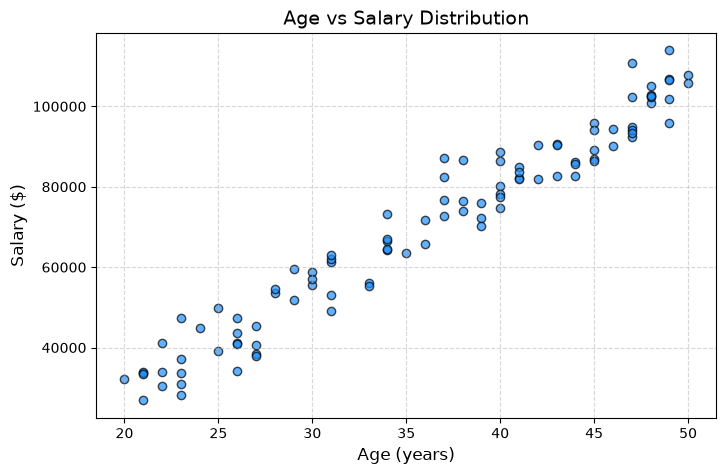

In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(df['Age'], df['Salary'], color='dodgerblue', edgecolor='black', alpha=0.7)
plt.title("Age vs Salary Distribution", fontsize=14)
plt.xlabel("Age (years)", fontsize=12)
plt.ylabel("Salary ($)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


## 3. Supervised Learning: Linear Regression


Model Slope (Coefficient): 2580.63
Model Intercept: -22355.00
R² Score: 0.9261
RMSE: 5768.29


/Users/bhavya/Desktop/ /Sem_3/ML/.venv/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


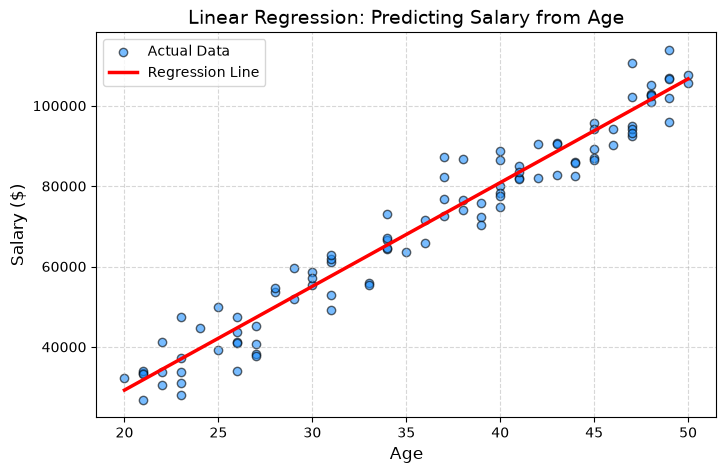

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Split data: 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred = lr_model.predict(X_test)

print(f"Model Slope (Coefficient): {lr_model.coef_[0]:.2f}")
print(f"Model Intercept: {lr_model.intercept_:.2f}")
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.2f}")

# Plot Regression Line
plt.figure(figsize=(8, 5))
plt.scatter(X, y, color='dodgerblue', edgecolor='black', alpha=0.6, label='Actual Data')
age_grid = np.linspace(20, 50, 100).reshape(-1, 1)
salary_pred_grid = lr_model.predict(age_grid)
plt.plot(age_grid, salary_pred_grid, color='red', linewidth=2.5, label='Regression Line')
plt.title("Linear Regression: Predicting Salary from Age", fontsize=14)
plt.xlabel("Age", fontsize=12)
plt.ylabel("Salary ($)", fontsize=12)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


---
# Part 2: K-Means Clustering (Unsupervised Learning)

### How K-Means Works:
1. **Unsupervised Algorithm**: Groups unlabeled data points into $K$ distinct clusters based on similarity (Euclidean distance).
2. **Centroid Initialization**: Selects $K$ initial cluster centers (using `k-means++` to avoid sub-optimal local minima).
3. **Assignment Step**: Assigns each data point to its closest centroid.
4. **Update Step**: Recomputes each centroid as the mean of all points assigned to that cluster.
5. **Convergence**: Repeats until centroids stop shifting or reach max iterations.
6. **Objective**: Minimize the **Within-Cluster Sum of Squares (WCSS / Inertia)**:
$$WCSS = \sum_{i=1}^{K} \sum_{x \in C_i} ||x - \mu_i||^2$$


### Step 1: Feature Scaling (Crucial for Distance-based Algorithms)
*Note: Age is in [20, 50] while Salary is in [30,000, 110,000]. Without scaling, Salary differences completely dominate the Euclidean distance calculation!*


In [11]:
from sklearn.preprocessing import StandardScaler

features = ['Age', 'Salary']
X_cluster = df[features]

# Standardize features so mean = 0 and std = 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print("Original Data (First 3 rows):")
print(X_cluster.head(3))
print("\nScaled Data (First 3 rows):")
print(np.round(X_scaled[:3], 3))


Original Data (First 3 rows):
   Age  Salary
0   26   34108
1   39   72280
2   48  100863

Scaled Data (First 3 rows):
[[-1.114 -1.519]
 [ 0.318  0.082]
 [ 1.31   1.28 ]]


### Step 2: The Elbow Method (Finding Optimal $K$)
We compute WCSS (Inertia) for $K = 1$ to $10$. The 'elbow' point indicates the optimal trade-off between cluster tightness and model complexity.


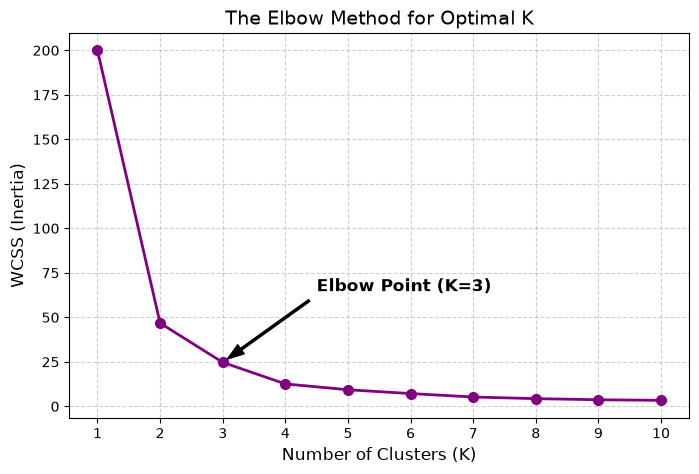

In [12]:
from sklearn.cluster import KMeans

wcss = []
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker='o', color='purple', linewidth=2, markersize=7)
plt.title("The Elbow Method for Optimal K", fontsize=14)
plt.xlabel("Number of Clusters (K)", fontsize=12)
plt.ylabel("WCSS (Inertia)", fontsize=12)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)

# Annotate Elbow
plt.annotate('Elbow Point (K=3)', xy=(3, wcss[2]), xytext=(4.5, wcss[2] + 40),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8),
             fontsize=12, fontweight='bold')
plt.show()


### Step 3: Train K-Means with Optimal $K=3$ and Evaluate


In [13]:
from sklearn.metrics import silhouette_score

optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Calculate Silhouette Score (-1 to 1; higher is better)
sil_score = silhouette_score(X_scaled, df['Cluster'])
print(f"Optimal K: {optimal_k}")
print(f"WCSS / Inertia: {kmeans.inertia_:.2f}")
print(f"Silhouette Score: {sil_score:.4f}")

# Extract centroids and transform back to original scale (Age & Salary)
centroids_scaled = kmeans.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)

print("\nCluster Centroids (Original Units):")
for i, (age_c, sal_c) in enumerate(centroids_original):
    print(f"Cluster {i}: Mean Age = {age_c:.1f} years, Mean Salary = ${sal_c:,.0f}")


Optimal K: 3
WCSS / Inertia: 24.72
Silhouette Score: 0.5461

Cluster Centroids (Original Units):
Cluster 0: Mean Age = 38.4 years, Mean Salary = $76,662
Cluster 1: Mean Age = 26.2 years, Mean Salary = $44,526
Cluster 2: Mean Age = 46.7 years, Mean Salary = $97,345


### Step 4: Visualize Clusters and Centroids


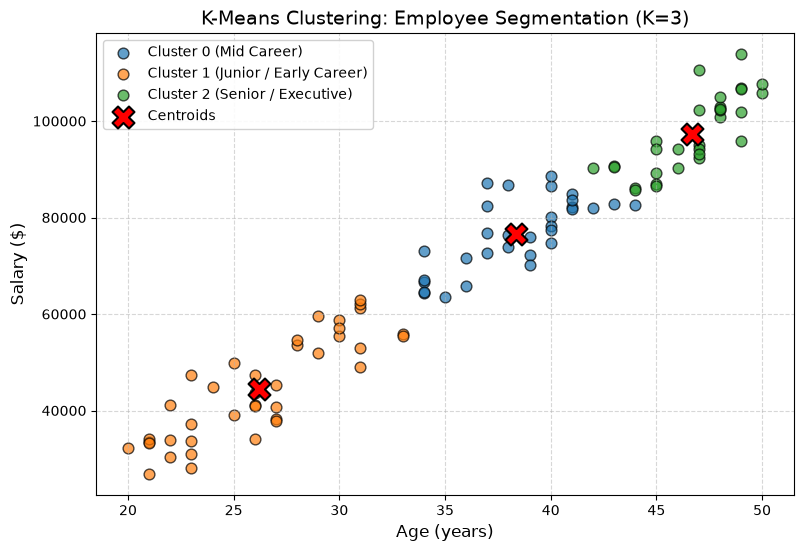

In [14]:
plt.figure(figsize=(9, 6))

colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
labels = ['Cluster 0 (Mid Career)', 'Cluster 1 (Junior / Early Career)', 'Cluster 2 (Senior / Executive)']

for i in range(optimal_k):
    cluster_points = df[df['Cluster'] == i]
    plt.scatter(cluster_points['Age'], cluster_points['Salary'],
                color=colors[i], label=labels[i], alpha=0.7, edgecolors='k', s=60)

# Plot Centroids
plt.scatter(centroids_original[:, 0], centroids_original[:, 1],
            color='red', marker='X', s=250, edgecolor='black', linewidth=1.5, label='Centroids')

plt.title("K-Means Clustering: Employee Segmentation (K=3)", fontsize=14)
plt.xlabel("Age (years)", fontsize=12)
plt.ylabel("Salary ($)", fontsize=12)
plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


### Step 5: Cluster Summary & Interpretation


In [15]:
# Summary statistics per cluster
cluster_summary = df.groupby('Cluster').agg({
    'Age': ['count', 'min', 'mean', 'max'],
    'Salary': ['min', 'mean', 'max']
}).round(1)

cluster_summary.columns = ['Count', 'Min Age', 'Avg Age', 'Max Age', 'Min Salary', 'Avg Salary', 'Max Salary']
cluster_summary


,Count,Min Age,Avg Age,Max Age,Min Salary,Avg Salary,Max Salary
Cluster,,,,,,,
0,31,34,38.4,44,63589,76662.1,88632
1,39,20,26.2,33,26880,44526.2,62933
2,30,42,46.7,50,85648,97345.2,113936


### Step 6: Predict Cluster for New Unseen Data


In [16]:
# Example new employee profiles
new_candidates = pd.DataFrame({
    'Age': [23, 35, 49],
    'Salary': [35000, 72000, 105000]
})

# Remember: New data MUST be scaled using the same fitted scaler!
new_candidates_scaled = scaler.transform(new_candidates)
predicted_clusters = kmeans.predict(new_candidates_scaled)

new_candidates['Predicted_Cluster'] = predicted_clusters
print("Predictions for New Candidates:")
print(new_candidates)


Predictions for New Candidates:
   Age  Salary  Predicted_Cluster
0   23   35000                  1
1   35   72000                  0
2   49  105000                  2
